# HSV Renk Segmentasyonu — Derviş

Görüntü BGR okunur, HSV uzayına dönüştürülür ve `cv2.inRange` ile sabit aralıktaki pikseller seçilir. OpenCV 8-bit gösterimde **H = 0–179**, S ve V = 0–255'tir.
Aralık **yalnızca G1/G2'de** seçilip dondurulmuştur; K1–K4 sonucu görüldükten sonra değiştirilmez.
- Maske alanı (%) = 100 × seçilen piksel / toplam piksel
- Baş örtüşmesi (%) = baş ROI içindeki seçili piksel oranı → dört sınıflı karar

In [1]:
from pathlib import Path
import sys
KOK = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "kaynak" / "analiz.py").is_file())
sys.path.insert(0, str(KOK))

import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from kaynak.veri import ayarlari_oku, veri_setini_oku, goruntu_oku, maske_oku
from kaynak.analiz import analiz_et
from kaynak.gorsel import bgr2rgb, kutulari_ciz, maske_bindir
ayarlar = ayarlari_oku()
kayitlar = veri_setini_oku()
pd.set_option("display.max_colwidth", 80)
print("Görüntüler:", ", ".join(f"{k['kimlik']} ({k['bolum']})" for k in kayitlar))

Görüntüler: G1 (gelistirme), G2 (gelistirme), K1 (kontrol), K2 (kontrol), K3 (kontrol), K4 (kontrol)


## 1. Dondurulmuş ayarlar ve karar kuralı

In [2]:
print("HSV aralığı:", ayarlar["renk_araliklari"]["HSV"])
print("Karar kuralı:", ayarlar["karar_kurali"]["kural"])

HSV aralığı: {'alt': [18, 120, 80], 'ust': [30, 255, 255], 'aciklama': 'OpenCV 8-bit: H 0-179, S ve V 0-255', 'gerekce': "Ödev yönergesindeki örnek aralık (H 18-30, S > 120, V > 80). G1'deki baret piksellerinin (etiketler/kalibrasyon/G1_baret_firca.png)  %87.1'ini yakalıyor ve renkli piksellerin %61.1'i baret; önceki başlangıç aralığı [18,80,80]-[50,255,255] %91.2 yakalayıp yalnızca %41.5 kesinlik veriyordu. G2'de seçilen alan %0."}
Karar kuralı: 1) Baş görünmüyorsa (bas_roi yok): belirsiz. 2) Görüntüdeki renkli alan < %2.5: baret_yok. 3) Baş bölgesindeki renkli piksel oranı >= %5: basta_baret. 4) Aksi halde: baret_var_basta_degil. Renk maskesi baret nesnesini kanıtlamaz; kural yalnızca renk ve konuma bakar.


## 2. Deney öncesi tahmin

In [3]:
tahminler = pd.read_csv(KOK / "belgeler/tahminler.csv")
benim = tahminler[(tahminler.uye == "Derviş")]
if benim.empty:
    print("UYARI: Bu deney için kayıtlı tahmin yok. Hoca: 'Tahmini olmayan deney puanlanmaz.'")
    print("Deneyi çalıştırmadan ÖNCE belgeler/tahminler.csv dosyasına iki cümle ekleyin.")
for _, t in benim.iterrows():
    print(f"[{t.kayit_tarihi}] {t.deney_kimligi}\n 1) {t.tahmin_1}\n 2) {t.tahmin_2}\n   ({t.durum})\n")

[2026-11-03] dervis_hsv_baseline
 1) HSV’nin renk tonu, doygunluk ve parlaklığı ayrı değerlendirmesi sayesinde değişen aydınlatma koşullarında sarı baret piksellerini RGB’den daha iyi seçebilmesini bekliyorum. Ancak çok düşük parlaklık, düşük doygunluk ve benzer renkli nesneler nedeniyle HSV’nin de kaçırma veya yanlış alarm üretebileceğini öngörüyorum.
 2) Sarı ekipman, yelek ve sarı ışık altındaki yüzeylerin baretle aynı HSV aralığına girebileceğini düşünüyorum. K4’te elde tutulan sarı baretin maskede seçilmesini, ancak baş ROI ile örtüşmesinin düşük kalmasını bekliyorum.
   (Derviş tarafından yazıldı (deney öncesi). Kimlikler önceki veri setine göre yazıldı: metindeki 'K2 düşük ışık' -> yeni K1 (loş ışık); 'K3 küçük baretler' -> yeni K2 (aynı görüntü); 'K1 başlar görünmüyor' -> önceki görüntü artık G2 (geliştirme); K4 yine elde baret.)



## 3. Geliştirme (G1, G2) — aralık seçimi yalnızca burada

In [4]:
def tablo(bolum):
    satirlar = []
    for k in veri_setini_oku(bolum):
        s = analiz_et(goruntu_oku(k["dosya"]), "HSV", ayarlar, k["bas_roi"], k["baret_kutulari"])
        satirlar.append({"Görüntü": k["kimlik"], "Koşul": k["kosul"], "Maske alanı (%)": round(s["alan_yuzde"], 2),
                         "Baş örtüşmesi (%)": None if s["ortusme_yuzde"] is None else round(s["ortusme_yuzde"], 2),
                         "Kuralın sınıfı": s["sinif"], "Doğru sınıf": k["dogru_sinif"],
                         "Doğru mu": s["sinif"] == k["dogru_sinif"]})
    return pd.DataFrame(satirlar)
tablo("gelistirme")

,Görüntü,Koşul,Maske alanı (%),Baş örtüşmesi (%),Kuralın sınıfı,Doğru sınıf,Doğru mu
0,G1,"Gün ışığı; sarı baret başta, yüz net görünür (normal ışık)",4.69,33.76,basta_baret,basta_baret,True
1,G2,"Gün ışığı; baş görünür, kumaş şapka, baret yok",0.00,0.00,baret_yok,baret_yok,True


## 4. Kontrol (K1–K4) — 4 maske ve dört sınıflı karar

In [5]:
kontrol = tablo("kontrol"); kontrol

,Görüntü,Koşul,Maske alanı (%),Baş örtüşmesi (%),Kuralın sınıfı,Doğru sınıf,Doğru mu
0,K1,"Loş, soğuk mavi iç mekân ışığı; sarı baret başta; sarı-yeşil reflektif yelek",0.81,12.69,baret_yok,basta_baret,False
1,K2,Uzak; küçük baş ve baret,0.03,17.88,baret_yok,basta_baret,False
2,K3,"Gün ışığı; başı açık işçi (kumaş şapka), sarı-turuncu iş makinesi (aynı renk...",1.46,2.57,baret_yok,baret_yok,True
3,K4,"Gün ışığı; sarı baret elde, başı açık ve görünür",17.01,0.00,baret_var_basta_degil,baret_var_basta_degil,True


In [6]:
print(f"Sınıf doğruluğu: {kontrol['Doğru mu'].sum()}/{len(kontrol)}")

Sınıf doğruluğu: 2/4


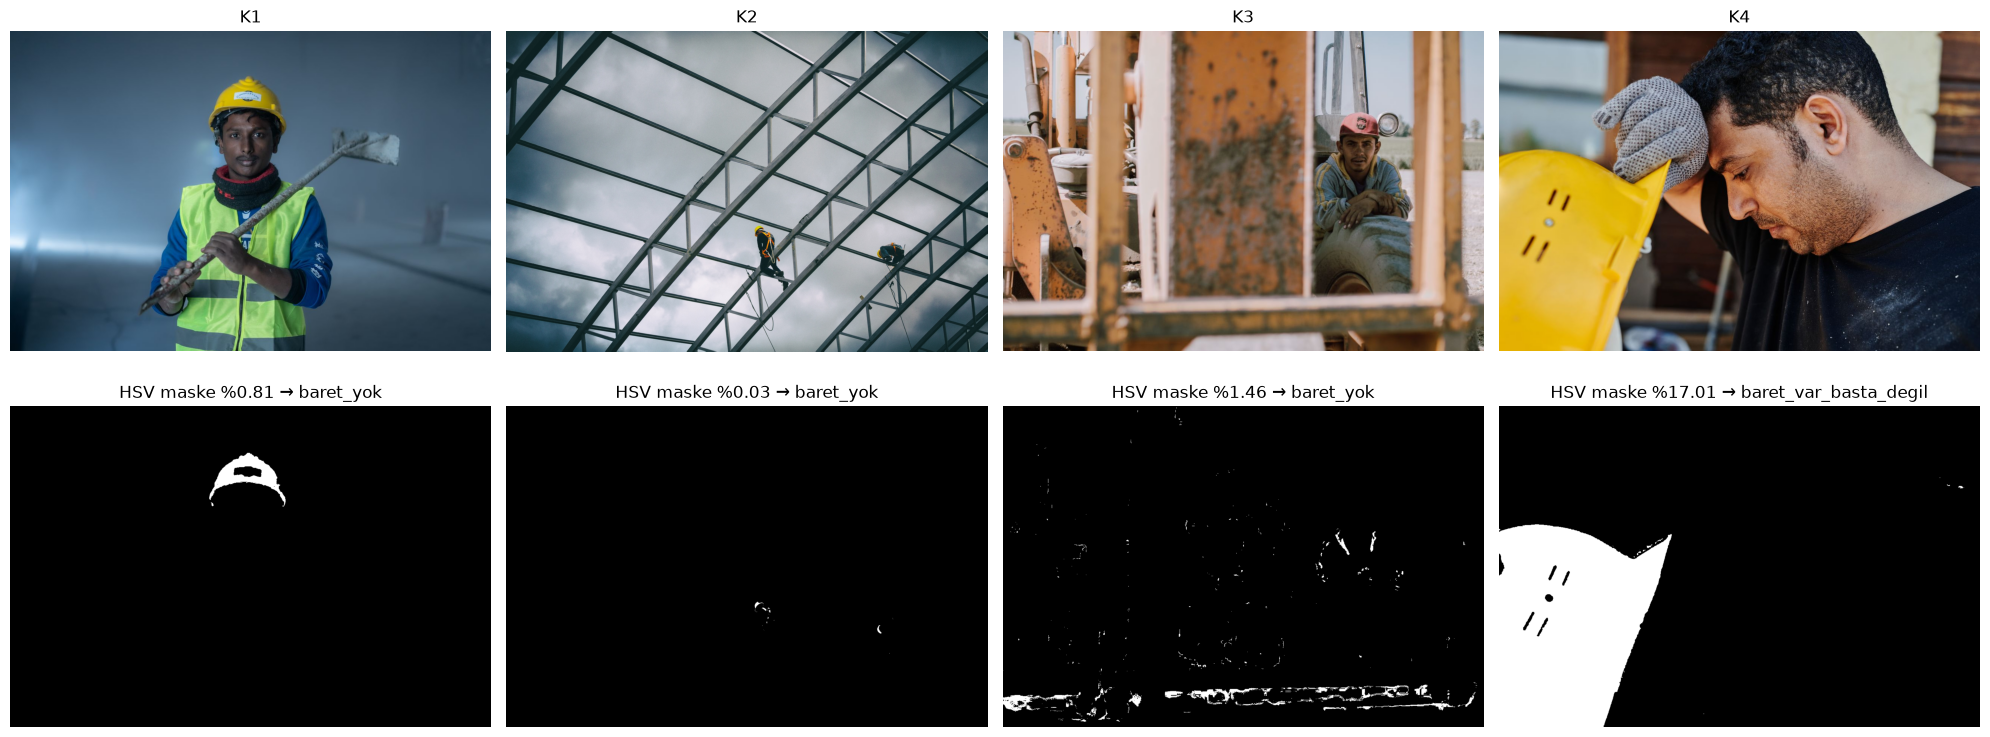

In [7]:
fig, eksen = plt.subplots(2, 4, figsize=(20, 8))
for i, k in enumerate(veri_setini_oku("kontrol")):
    g = goruntu_oku(k["dosya"]); s = analiz_et(g, "HSV", ayarlar, k["bas_roi"])
    eksen[0, i].imshow(bgr2rgb(g)); eksen[0, i].set_title(k["kimlik"])
    eksen[1, i].imshow(s["maske"], cmap="gray"); eksen[1, i].set_title(f"HSV maske %{s['alan_yuzde']:.2f} → {s['sinif']}")
    for e in eksen[:, i]: e.axis("off")
plt.tight_layout(); plt.show()

## 5. RGB ile karşılaştırma (aynı görüntü kimlikleri, aynı ölçüler)

In [8]:
t = pd.read_csv(KOK / "sonuclar/temel_sonuclar.csv")
t[t.bolum == "kontrol"].pivot(index="kimlik", columns="yontem", values=["maske_alani_yuzde", "bas_ortusmesi_yuzde", "kural_sinifi", "dogru_mu"])

maske_alani_yuzde        bas_ortusmesi_yuzde         \
yontem               HSV    RGB                 HSV    RGB   
kimlik                                                       
K1                  0.81    0.4               12.69   6.08   
K2                  0.03   0.03               17.88  17.74   
K3                  1.46   2.65                2.57    0.0   
K4                 17.01  17.59                 0.0   2.61   

                 kural_sinifi                        dogru_mu         
yontem                    HSV                    RGB      HSV    RGB  
kimlik                                                                
K1                  baret_yok              baret_yok    hayir  hayir  
K2                  baret_yok              baret_yok    hayir  hayir  
K3                  baret_yok  baret_var_basta_degil     evet  hayir  
K4      baret_var_basta_degil  baret_var_basta_degil     evet   evet

## Hata yorumu, sınırlılık ve sonraki kontrol

1. **Tahminim tuttu mu?**
   Tahminim kısmen tuttu. HSV dört görüntünün ikisini, RGB ise birini doğru sınıflandırdı. K1’de HSV baş bölgesindeki baret rengini RGB’den daha fazla seçti; ancak ortak karar kuralı nedeniyle sınıf yine yanlış çıktı. Bu yüzden HSV’nin bu veri setinde avantaj sağladığını, fakat her durumda doğru karar vermediğini gördüm.

2. **Seçtiğim hata, nedeni ve sonraki kontrol:**
   K1’deki yanlış sınıf kararını seçtim. HSV bareti bulmasına ve baş örtüşmesi %12,69 olmasına rağmen toplam maske alanı %0,81 ile %2,5 eşiğinin altında kaldığı için “baret yok” sonucu çıktı. Sonraki kontrolde baş bölgesindeki renk oranını önceleyen bir kuralı geliştirme görüntülerinde incelerdim; mevcut kontrol sonuçlarına bakarak eşikleri değiştirmezdim.

3. **S1 — HSV hangi koşullarda başarısız olur?**
   Görüntü çok karanlık olduğunda, renk doygunluğu azaldığında veya aydınlatma nesnenin görünen rengini değiştirdiğinde HSV başarısız olabilir. Baret pikselleri seçilen H, S veya V aralığının dışında kaldığında maske bareti kaçırabilir.

4. **S2 — Aynı renkteki başka bir nesnenin seçilmesi ne anlatıyor?**
   Bu durum, yöntemin nesnenin baret olduğunu anlamadığını, yalnızca belirlediğim renk aralığına uyan pikselleri seçtiğini gösteriyor. K3’te HSV’nin 33 yanlış kutu üretmesi bunun bir örneği. Görüntünün sınıfının doğru çıkması, bu yanlış kutuların ortadan kalktığı anlamına gelmiyor.